In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [14]:
df=pd.read_csv(r"C:\Users\racha\Downloads\student_risk_ml_dataset.csv")
df.head()

,student_id,age,attendance_pct,previous_marks_pct,assignment_score_pct,internal_marks_pct,study_hours_per_day,previous_failures,absences,assignment_completion_pct,class_participation_pct,parent_support,internet_access,extracurricular,transport_mode,at_risk
0,STU1001,21,78.8,75.5,65.6,63.8,6.4,0,17,89.7,82.7,High,Yes,No,Public,0
1,STU1002,18,100.0,80.9,60.5,98.5,6.7,0,7,100.0,100.0,Medium,Yes,Yes,Public,0
2,STU1003,19,83.3,83.1,60.6,65.2,6.7,1,21,93.4,78.7,Low,No,No,Public,1
3,STU1004,21,89.8,91.0,42.7,74.1,2.6,0,10,91.7,60.3,Medium,Yes,Yes,Public,0
4,STU1005,17,75.4,58.3,80.2,82.6,1.1,1,19,94.4,69.6,Medium,No,No,Public,1


In [15]:
df.isnull().sum()

student_id                   0
age                          0
attendance_pct               0
previous_marks_pct           0
assignment_score_pct         0
internal_marks_pct           0
study_hours_per_day          0
previous_failures            0
absences                     0
assignment_completion_pct    0
class_participation_pct      0
parent_support               0
internet_access              0
extracurricular              0
transport_mode               0
at_risk                      0
dtype: int64

In [16]:
X=df.drop(columns=['at_risk','student_id'])

In [17]:
X.head()

,age,attendance_pct,previous_marks_pct,assignment_score_pct,internal_marks_pct,study_hours_per_day,previous_failures,absences,assignment_completion_pct,class_participation_pct,parent_support,internet_access,extracurricular,transport_mode
0,21,78.8,75.5,65.6,63.8,6.4,0,17,89.7,82.7,High,Yes,No,Public
1,18,100.0,80.9,60.5,98.5,6.7,0,7,100.0,100.0,Medium,Yes,Yes,Public
2,19,83.3,83.1,60.6,65.2,6.7,1,21,93.4,78.7,Low,No,No,Public
3,21,89.8,91.0,42.7,74.1,2.6,0,10,91.7,60.3,Medium,Yes,Yes,Public
4,17,75.4,58.3,80.2,82.6,1.1,1,19,94.4,69.6,Medium,No,No,Public


In [18]:
y=df['at_risk']
y.head(2)

0    0
1    0
Name: at_risk, dtype: int64

In [19]:
from sklearn.preprocessing import LabelEncoder

In [20]:
encoder=LabelEncoder()

In [30]:
X['parent_support']=encoder.fit_transform(X['parent_support'])

In [31]:
X['internet_access']=encoder.fit_transform(X['internet_access'])

In [32]:
X['extracurricular']=encoder.fit_transform(X['extracurricular'])

In [33]:
X['transport_mode']=encoder.fit_transform(X['transport_mode'])

In [34]:
X.head()

,age,attendance_pct,previous_marks_pct,assignment_score_pct,internal_marks_pct,study_hours_per_day,previous_failures,absences,assignment_completion_pct,class_participation_pct,parent_support,internet_access,extracurricular,transport_mode,\tparent_support
0,21,78.8,75.5,65.6,63.8,6.4,0,17,89.7,82.7,0,1,0,1,0
1,18,100.0,80.9,60.5,98.5,6.7,0,7,100.0,100.0,2,1,1,1,2
2,19,83.3,83.1,60.6,65.2,6.7,1,21,93.4,78.7,1,0,0,1,1
3,21,89.8,91.0,42.7,74.1,2.6,0,10,91.7,60.3,2,1,1,1,2
4,17,75.4,58.3,80.2,82.6,1.1,1,19,94.4,69.6,2,0,0,1,2


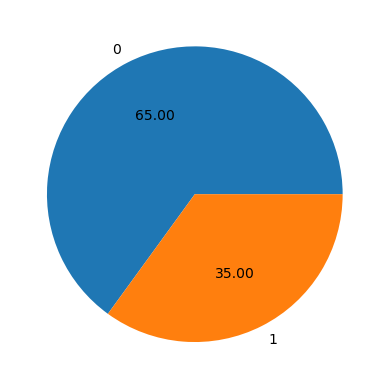

In [36]:
plt.pie(df['at_risk'].value_counts(),labels=['0','1'],autopct="%0.2f")
plt.show()

In [37]:
from sklearn.model_selection import train_test_split

In [39]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [58]:
models={
    "LogisticRegression:":LogisticRegression(max_iter=1000,class_weight='balanced'),
    "DecisionTreeClassifier:" :DecisionTreeClassifier(random_state=42,class_weight='balanced'),
     "RandomForestClassifier:" :RandomForestClassifier(random_state=42,class_weight='balanced')
}

In [59]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)

In [62]:
results = []
for name , model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        
    })

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [65]:
comparsion=pd.DataFrame(results)

In [68]:
print(comparsion.sort_values(by="F1 Score",ascending=False))

                     Model  Accuracy  Precision    Recall  F1 Score
2  RandomForestClassifier:  0.850000   0.892857  0.892857  0.892857
0      LogisticRegression:  0.841667   0.922078  0.845238  0.881988
1  DecisionTreeClassifier:  0.725000   0.849315  0.738095  0.789809


In [69]:
from sklearn.model_selection import cross_val_score

best_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=42
)

scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1 scores:", scores)
print("Mean F1:", scores.mean())

F1 scores: [0.81355932 0.84615385 0.848      0.85714286 0.85074627]
Mean F1: 0.8431204587974637


In [70]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20, None],
    "min_samples_split": [2, 5, 10]
}

grid = GridSearchCV(
    RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1: 0.8558904603491723


In [71]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Accuracy: 0.8416666666666667
Precision: 0.891566265060241
Recall: 0.8809523809523809
F1: 0.8862275449101796


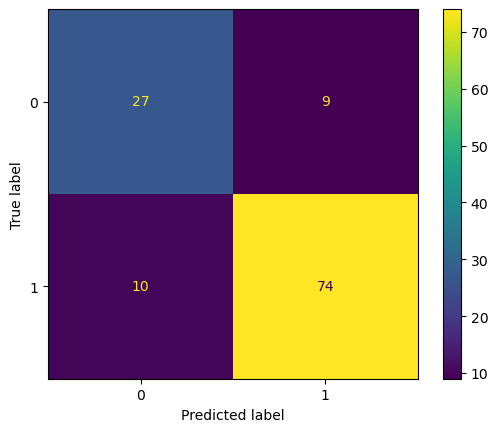

In [72]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.show()

In [74]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

                      Feature  Importance
1              attendance_pct    0.176861
7                    absences    0.145220
5         study_hours_per_day    0.099523
2          previous_marks_pct    0.093136
4          internal_marks_pct    0.092843
9     class_participation_pct    0.081421
6           previous_failures    0.070087
3        assignment_score_pct    0.068911
8   assignment_completion_pct    0.063258
0                         age    0.033513
10             parent_support    0.020332
13             transport_mode    0.019569
14           \tparent_support    0.017756
11            internet_access    0.009379
12            extracurricular    0.008190


In [ ]:
import joblib

joblib.dump(best_model, ".pkl")